# សប្ដាហ៍ទី 9 · ការផ្គុំប្រព័ន្ធបញ្ចូលគ្នា

អ្នកបានបង្កើតគ្រប់ផ្នែកនៃប្រព័ន្ធរួចហើយ។ សប្ដាហ៍នេះ អ្នកនឹងឃើញថា ផ្នែកទាំងនោះភ្ជាប់គ្នាយ៉ាងដូចម្ដេច ដាក់ការសម្រេចចិត្តទាំងអស់របស់អ្នកនៅកន្លែងតែមួយ ហើយចាប់ផ្ដើម Final project របស់អ្នក។

| | |
|---|---|
| **សំណួរសប្ដាហ៍នេះ** | តើផ្នែកនានានៃប្រព័ន្ធមួយ ភ្ជាប់គ្នាយ៉ាងដូចម្ដេច ហើយការសម្រេចចិត្តរបស់អ្នក គួរនៅកន្លែងណា? |
| **Python ដែលអ្នកនឹងរៀន** | module, `import`, `if __name__ == "__main__":`; ការ run file `.py` ដោយប្រើ `subprocess.run` (អ្នកគ្រាន់តែអាន និង run cell ទាំងនេះ មិនចាំបាច់សរសេរវាទេ)។ គ្មាន syntax ថ្មីផ្សេងទៀតទេ។ |
| **គោលការណ៍ទី 9** | **បំបែកអ្វីដែលប្រែប្រួល ចេញពីអ្វីដែលនៅដដែល។** ទុកការសម្រេចចិត្ត (settings និងវិធាន) ឱ្យដាច់ពីគ្រឿងម៉ាស៊ីន (ការរក្សាទុក អេក្រង់)។ |
| **ផ្នែកដែលអ្នកបង្កើត** | ប្រព័ន្ធផ្ទាល់ខ្លួនរបស់អ្នក: `bridge.System(MY_SETTINGS, hooks=...)` ដែលពិនិត្យដោយ `verify()` និង កម្រិតទី 1 នៃ Final project |

*Campus FoodBridge ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

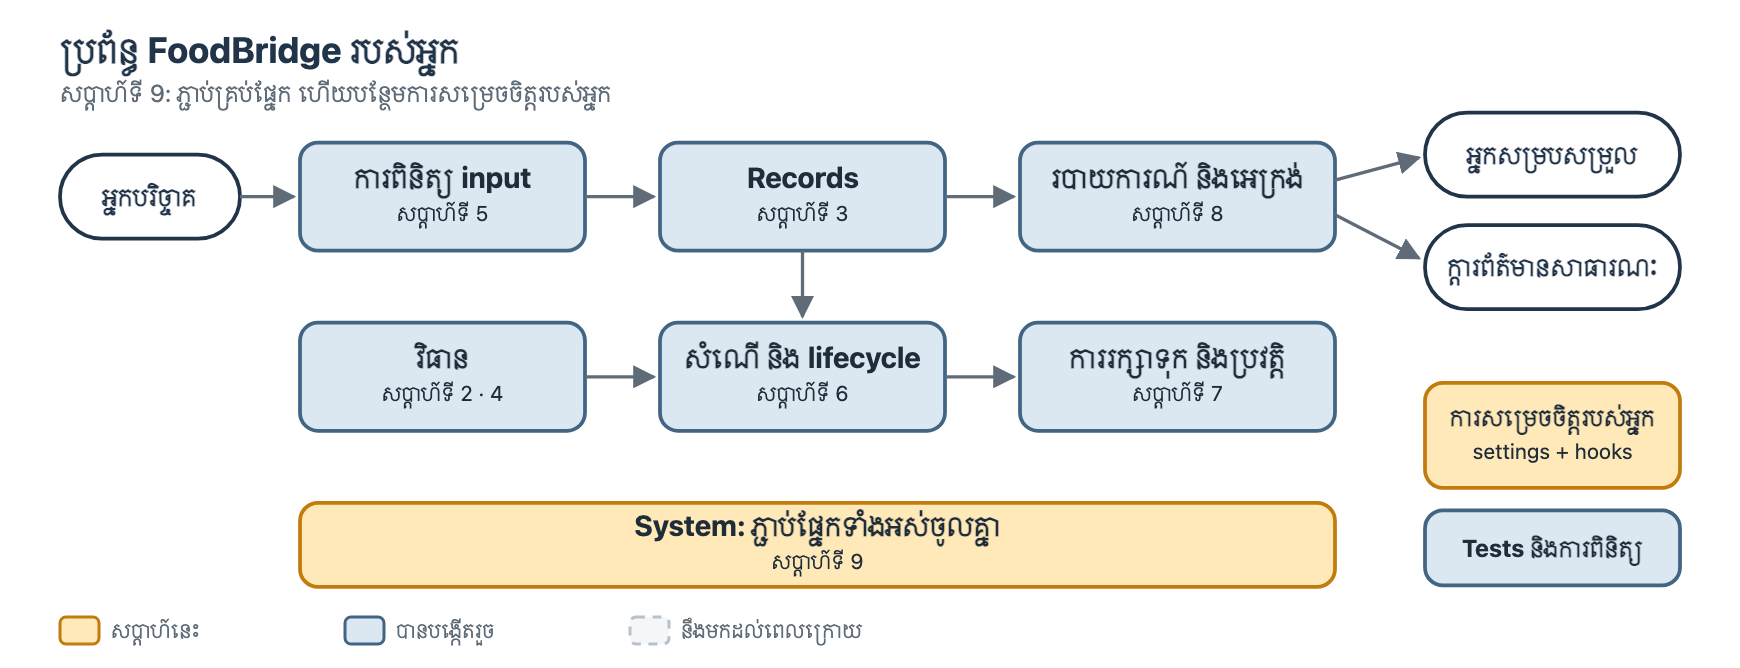

## មុនពេលចាប់ផ្ដើម

1. **File → Save a copy in Drive** រួចធ្វើការនៅក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. Run setup cell។ Run វាម្ដងទៀត បន្ទាប់ពី runtime ចាប់ផ្ដើមឡើងវិញ (restart)។
3. ⭐ = មូលដ្ឋាន សម្រាប់គ្រប់គ្នា, ⭐⭐ = បន្ថែម (ស្រេចចិត្ត)។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ FoodBridge
# វាដកយក (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
bridge.set_language("km")     # screens and checks in Khmer
print("✅ ប្រព័ន្ធ FoodBridge រួចរាល់ហើយ (version " + bridge.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")


## វគ្គទី 1 · រៀន: ផ្នែកនានា module និង program (30 នាទី)

### គំនិតសំខាន់: អ្វីដែលប្រែប្រួល និងអ្វីដែលនៅដដែល

គិតពីទូរសព្ទរបស់អ្នក។ អ្នកប្ដូរសំឡេងរោទ៍ ភាសា និងពន្លឺអេក្រង់ជាច្រើនដង។ អ្នកធ្វើវានៅក្នុង **Settings**។ អ្នកមិនដែលបើកទូរសព្ទ ដើម្បីតខ្សែភ្លើងខាងក្នុងឡើងវិញទេ។ វិស្វករបានទុកអ្វីដែលមនុស្សសម្រេចចិត្ត ឱ្យដាច់ពីគ្រឿងម៉ាស៊ីន (អេក្រង់ ថ្ម វិទ្យុ)។ ដូច្នេះ ការផ្លាស់ប្ដូរមួយគឺតូច និងមានសុវត្ថិភាព ហើយវាមិនអាចធ្វើឱ្យទូរសព្ទខូចបានទេ។

ប្រព័ន្ធរបស់យើងក៏ដូច្នេះដែរ។ **គ្រឿងម៉ាស៊ីន** (machinery: ការពិនិត្យ input ការរក្សា records ការរក្សាទុក ការបង្ហាញអេក្រង់) នៅដដែល។ **ការសម្រេចចិត្ត** របស់អ្នក (ចំនួនអប្បបរមាសម្រាប់ក្រុម fields សាធារណៈ វិធានផ្ទាល់ខ្លួនរបស់អ្នក) ប្រែប្រួល។ ការសម្រេចចិត្តទាំងនោះនៅតែពីរកន្លែងប៉ុណ្ណោះ: **settings** និង **hooks**។

### 1 · module គឺជា file `.py` មួយ

**module** គឺជា file Python ដែលមាន function និង value នៅខាងក្នុង។ `import` ផ្ទុក module នោះចូលមក។ បន្ទាប់មក `module.name` មានន័យថា *"ឈ្មោះ name ដែលនៅក្នុង module នោះ"*។ សញ្ញាចុច (dot) ធ្វើឱ្យឈ្មោះពី module ផ្សេងៗគ្នា មិនច្រឡំគ្នា។

`math` មកជាមួយ Python ស្រាប់។ ប្រព័ន្ធ FoodBridge ក៏ផ្សំឡើងពី module ដែរ។ តាំងពីសប្ដាហ៍ទី 1 មក setup cell បាន run `import foodbridge as bridge`។ ពាក្យ `as` ដាក់ឈ្មោះខ្លីមួយឱ្យ module។

🤔 **ទាយមើល** ថា `bridge.rules.pickup_label(30, False)` print អ្វី រួច run cell។

In [ ]:
import math
print(math.sqrt(49))
print(math.pi)

import foodbridge as bridge
print(bridge.rules.pickup_label(30, True))
print(bridge.rules.pickup_label(30, False))
print(bridge.records.total_portions(bridge.sample_records()))

**ការទាយ:** …  **លទ្ធផល:** …  **ហេតុអ្វី:** …

### 2 · ផែនទីនៃផ្នែកនានា

ផ្នែកនីមួយៗដែលអ្នកបានបង្កើត នៅក្នុង module ផ្ទាល់ខ្លួនរបស់វា។ `README.md` របស់ kit មានផែនទីមួយ។ module នីមួយៗក៏ចាប់ផ្ដើមដោយការពិពណ៌នាខ្លីមួយ ដែលហៅថា **docstring** របស់វា។ Python រក្សាវាទុកក្នុង `__doc__` ហើយរក្សាឈ្មោះរបស់ module ខ្លួនឯងក្នុង `__name__`។ Run cell ដើម្បីអានទាំងពីរ។

In [ ]:
with open("foodbridge_kit/README.md") as file:
    readme = file.read()

start = readme.find("## Map of the parts")   # ទីតាំងដែលផែនទីចាប់ផ្ដើម
print(readme[start:])                       # [start:] មានន័យថា: ពីទីនោះ រហូតដល់ចុងបញ្ចប់

for module in [bridge.rules, bridge.records, bridge.validation, bridge.models, bridge.storage, bridge.reports]:
    first_line = module.__doc__.splitlines()[0]
    print(module.__name__, "·", first_line)

🤔 អ្នកសម្របសម្រួលម្នាក់និយាយថា: *"file ដែលបានរក្សាទុកបានខូច ពេលកុំព្យូទ័រយួរដៃរលត់ភ្លាមៗ។"* តើអ្នកនឹងបើក module ណាមុនគេ? ចុះបើក្ដារព័ត៌មានសាធារណៈបង្ហាញជួរឈរខុស តើអ្នកនឹងបើក module ណា?

**ចម្លើយរបស់ខ្ញុំ:** …

### 3 · កន្លែងពីរសម្រាប់ការសម្រេចចិត្តរបស់អ្នក: settings និង hooks

`bridge.DEFAULTS` ផ្ទុក **setting** នីមួយៗ ជាមួយ default value របស់វា។ អ្នកប្ដូរ setting មួយ ដោយដាក់ឈ្មោះដដែលនោះក្នុង `MY_SETTINGS`។ អ្នកមិនដែលកែ file របស់ kit ទេ។ `bridge.HOOKS` រាយ function ដែលអ្នកអាចជំនួសដោយ function ផ្ទាល់ខ្លួនរបស់អ្នក និងចំនួន input ដែល function នីមួយៗទទួល។

In [ ]:
print(len(bridge.DEFAULTS), "settings")
for name in bridge.DEFAULTS:
    print(f"{name:28} {bridge.DEFAULTS[name]}")
print()
print(bridge.HOOKS)

🤔 តើអ្នកបានសរសេរ hook មួយណានៅសប្ដាហ៍ទី 2? មួយណានៅសប្ដាហ៍ទី 8? តើ `can_move` ទទួល input ប៉ុន្មាន ហើយ input ទាំងនោះជាអ្វីខ្លះ?

**ចម្លើយរបស់ខ្ញុំ:** …

### 4 · របៀបដែល `System` ភ្ជាប់ផ្នែកនានា

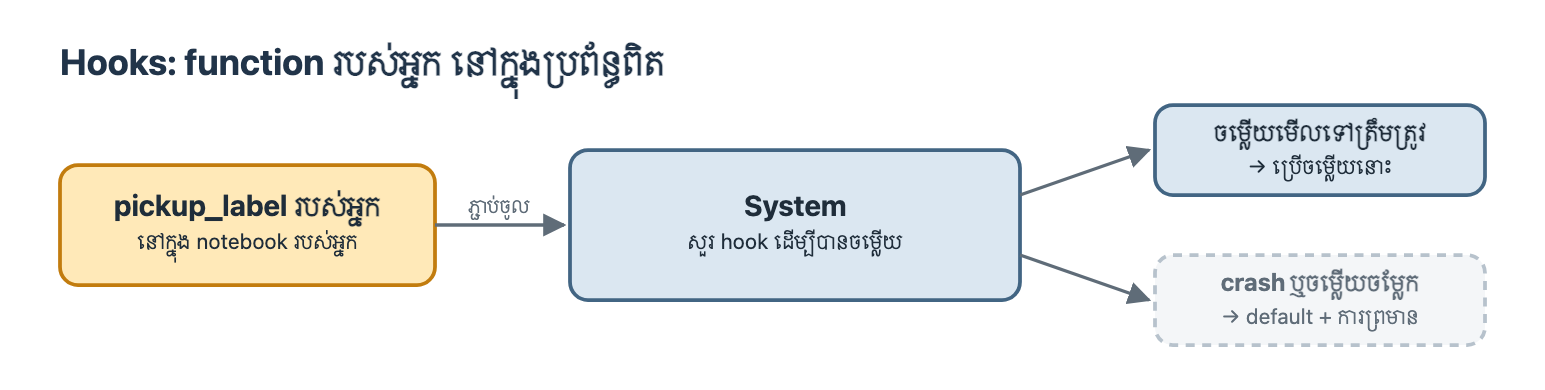

`bridge.System(MY_SETTINGS, hooks=...)` ធ្វើការងារបី:

1. វាបង្កើត **settings ពេញលេញ**: default បូកនឹងការផ្លាស់ប្ដូររបស់អ្នក។ ឈ្មោះដែលសរសេរខុស ត្រូវបានរំលង ជាមួយការព្រមាន ⚠️។
2. វារៀបចំ **default function** មួយ សម្រាប់ hook នីមួយៗ រួចភ្ជាប់ function របស់អ្នកចូល។
3. រាល់ពេលដែលវាត្រូវការចម្លើយ វា **សួរ hook**។ បើ function របស់អ្នក crash ឬផ្ដល់ចម្លើយចម្លែក ប្រព័ន្ធប្រាប់មូលហេតុ (តែម្ដង) ហើយប្រើ default ជំនួស ដូច្នេះថ្ងៃនោះនៅតែបន្តទៅមុខ។

🤔 ប្រព័ន្ធនេះមាន setting មួយដែលសរសេរខុស និង hook មួយដែលស្រែក។ **ទាយមើល** pickup label ទាំងពីរ រួច run។

In [ ]:
def shouting_label(portions, approved):
    return "TEAM!"            # មិនមែនជា "hold", "team" ឬ "standard" ទេ

test_system = bridge.System({"TEAM_PICKUP_MIN_PORTION": 25}, hooks={"pickup_label": shouting_label})
test_system.run_day(show=False)
for offer_id in ["F001", "F004"]:
    offer = test_system.get(offer_id)
    print(offer_id, offer.portions, "portions →", test_system.label(offer))

**ការទាយ:** …  **លទ្ធផល:** …  **ហេតុអ្វី:** …

ប្រព័ន្ធមិនដែលឈប់ទេ។ វាបានបដិសេធ setting ខុស និងចម្លើយខុស ប្រាប់មូលហេតុជាពាក្យងាយៗ ហើយរក្សាចំនួនអប្បបរមាសម្រាប់ក្រុមនៅ 20 ដដែល។ នោះហើយជា safe failure (បរាជ័យដោយសុវត្ថិភាព)។ វាក៏ជាការព្រមានមួយសម្រាប់អ្នកដែរ: បើអ្នកមិនអានបន្ទាត់ ⚠️ ទេ អ្នកអាចគិតថា function របស់អ្នកដំណើរការ ខណៈដែលតាមពិតវាមិនដំណើរការសោះ។

### 5 · ការ run file `.py` ក្នុង process ថ្មីមួយ

notebook ចងចាំអ្វីៗទាំងអស់ដែលអ្នកបាន run។ program ពិតប្រាកដចាប់ផ្ដើម **ថ្មីស្រឡាង**: វាដឹងតែអ្វីដែលមាននៅក្នុង file របស់វាប៉ុណ្ណោះ។ module `subprocess` របស់ Python អាចចាប់ផ្ដើម Python ថ្មីមួយ ហើយ run file មួយ ដូចដែល terminal ធ្វើដែរ។

In [ ]:
import subprocess
import sys

with open("hello.py", "w") as file:
    file.write('print("Hello from hello.py")\n')
    file.write("print(2 + 3)\n")

result = subprocess.run([sys.executable, "hello.py"], capture_output=True, text=True)
print("It printed:")
print(result.stdout)
print("Return code:", result.returncode)

- `sys.executable` គឺជា Python ដែលកំពុង run notebook នេះ។ យើងសុំឱ្យវា run `hello.py`។
- `capture_output=True` ប្រមូលអ្វីដែល program print។ `text=True` ផ្ដល់វាមកយើងជា text។
- `result.stdout` គឺជា output ធម្មតា។ `result.stderr` ផ្ទុកសារ error។ return code `0` មានន័យថា *គ្មាន error*។

🤔 notebook ស្គាល់ `secret` ខាងក្រោម។ តើ process ថ្មីស្គាល់វាដែរឬទេ? **ទាយមើល** រួច run។

In [ ]:
secret = "only in this notebook"

with open("ask.py", "w") as file:
    file.write("print(secret)\n")

result = subprocess.run([sys.executable, "ask.py"], capture_output=True, text=True)
print("Return code:", result.returncode)
print("Last line of the error:", result.stderr.splitlines()[-1])

**ការទាយ:** …  **លទ្ធផល:** …  **ហេតុអ្វី:** …

process ថ្មីគឺស្មោះត្រង់: បើ program របស់អ្នកត្រូវការអ្វីមួយ អ្វីនោះត្រូវតែមាននៅក្នុង program។ សប្ដាហ៍ក្រោយ អ្នកនឹងប្រើគំនិតនេះ ដើម្បីពិនិត្យថា notebook ទាំងមូលរបស់អ្នក run បាន ពីការចាប់ផ្ដើមស្អាត (clean start)។

### 6 · import file មួយ ឬ run វា: `if __name__ == "__main__":`

Python ផ្ដល់ `__name__` មួយឱ្យ module នីមួយៗ។ ពេលអ្នក **run** file មួយ `__name__` របស់វាគឺ `"__main__"`។ ពេល file ផ្សេងទៀត **import** វា `__name__` របស់វាគឺជាឈ្មោះ module របស់វា។ notebook ខ្លួនឯងក៏ត្រូវបាន run ដែរ ដូច្នេះ `__name__` របស់វាក៏ជា `"__main__"` ដែរ (មើលបន្ទាត់ទីមួយនៃ cell)។

បន្ទាត់ `if __name__ == "__main__":` មានន័យថា *"ធ្វើការនេះ តែពេលខ្ញុំត្រូវបាន run ប៉ុណ្ណោះ មិនមែនពេលខ្ញុំត្រូវបាន import ទេ"*។ វាអនុញ្ញាតឱ្យ file មួយ ជាទាំង **program** និង **module**។ នៅទីនេះ `shop.py` មាន function មានប្រយោជន៍មួយ និង demo តូចមួយ។ `main.py` import `shop` ដើម្បីប្រើ function នោះ។

In [ ]:
print("This notebook says: my __name__ is", __name__)

shop_code = '''
TAX_RATE = 0.10

def price_with_tax(price):
    return round(price * (1 + TAX_RATE), 2)

print("shop.py says: my __name__ is", __name__)

if __name__ == "__main__":
    print("Demo: 100 with tax is", price_with_tax(100))
'''

main_code = '''
import shop

print("main.py says: my __name__ is", __name__)
print("main.py uses shop:", shop.price_with_tax(50))
'''

with open("shop.py", "w") as file:
    file.write(shop_code)
with open("main.py", "w") as file:
    file.write(main_code)

print(subprocess.run([sys.executable, "shop.py"], capture_output=True, text=True).stdout)

🤔 ឥឡូវ run `main.py`។ វា import `shop`។ **ទាយមើល** ថាបន្ទាត់ណាខ្លះនឹងបង្ហាញ។ តើបន្ទាត់ demo បង្ហាញដែរឬទេ?

In [ ]:
print(subprocess.run([sys.executable, "main.py"], capture_output=True, text=True).stdout)

**ការទាយ:** …  **លទ្ធផល:** …  **ហេតុអ្វី:** …

program របស់ kit ក៏ប្រើ guard ដូចគ្នានេះដែរ។ បន្ទាត់ចុងក្រោយនៃ `run_web.py` គឺ:

```python
if __name__ == "__main__":
    main()
```

ដោយសារ guard នេះ file ផ្សេងទៀតអាច import `run_web` បាន ដោយមិនចាប់ផ្ដើម web server ដោយអចេតនា។

### 7 · Run test ផ្ទាល់របស់ kit ក្នុង process ថ្មីមួយ

kit មាន test ផ្ទាល់ខ្លួននៅក្នុង `foodbridge_kit/tests/`។ `run_tests.py` run test ទាំងអស់។ យើង run វាក្នុង process ថ្មីមួយ ពីខាងក្នុង folder របស់ kit (`cwd=` មានន័យថា *"ចាប់ផ្ដើមនៅក្នុង folder នេះ"*)។

In [ ]:
kit_tests = subprocess.run([sys.executable, "run_tests.py"], cwd="foodbridge_kit",
                           capture_output=True, text=True)
lines = kit_tests.stdout.splitlines()
for line in lines:
    if "test_" in line and (line.startswith("✅") or line.startswith("❌")):
        print(line)
print(lines[-1])                           # បន្ទាត់ចុងក្រោយ រាប់ test ដែលជាប់ និងធ្លាក់

🤔 test ទាំងនេះប្រើ settings **default**។ តើវានៅតែជាប់ដែរឬទេ បន្ទាប់ពីអ្នកប្ដូរ `TEAM_PICKUP_MIN_PORTIONS` ក្នុង `MY_SETTINGS` ផ្ទាល់ខ្លួនរបស់អ្នក? ហេតុអ្វី?

**ចម្លើយរបស់ខ្ញុំ:** …

## វគ្គទី 2 · អនុវត្ត និងវាយតម្លៃ (60 នាទី)

### ⭐ P1 · តើការសម្រេចចិត្តនេះនៅកន្លែងណា?

អ្នកសម្របសម្រួលផ្ញើការស្នើសុំបួន។ ការស្នើសុំនីមួយៗគឺជា **ការសម្រេចចិត្ត** មួយ ដូច្នេះនីមួយៗគឺជា setting មួយ។ សរសេរមួយបន្ទាត់ សម្រាប់ការស្នើសុំនីមួយៗក្នុង `CHANGES`។ ប្រើឈ្មោះដែលមានក្នុង `bridge.DEFAULTS` (វគ្គទី 1 ផ្នែកទី 3)។

1. *"ចាប់ពីពេលនេះតទៅ សូមបញ្ជូនក្រុមមួយ ចាប់ពី 25 ចំណែកឡើងទៅ។"*
2. *"អ្នកបរិច្ចាគអាចផ្ដល់បាន រហូតដល់ 300 ចំណែក។"*
3. *"បង្ហាញម៉ោងនៅសល់ នៅលើក្ដារព័ត៌មានសាធារណៈ ដើម្បីឱ្យអង្គការដៃគូអាចរៀបចំផែនការបាន។"*
4. *"Sunflower Youth Club ចូលរួមជាអង្គការដៃគូថ្មី។"* (រក្សាអង្គការដៃគូចាស់ទាំងបីទុក។)

In [ ]:
CHANGES = {
    # TODO: មួយបន្ទាត់ សម្រាប់ការស្នើសុំនីមួយៗ ឧទាហរណ៍  "SOME_SETTING": value,
}

In [ ]:
print("✅" if len(CHANGES) == 4 else "❌", len(CHANGES), "of 4 requests written")
for name in CHANGES:
    print("✅" if name in bridge.DEFAULTS else "❌", name)

changed_system = bridge.System(CHANGES)
changed_system.run_day(show=False)
print(changed_system.report("public"))

🤔 តើអ្នកបានប្ដូរគ្រឿងម៉ាស៊ីនរបស់ kit ប៉ុន្មានបន្ទាត់? ការស្នើសុំទីប្រាំនិយាយថា: *"ផ្ញើសារ SMS ទៅអង្គការដៃគូ ពេលអាហារត្រូវបានទៅយក។"* តើនោះជា setting ឬជាគ្រឿងម៉ាស៊ីនថ្មី? ហេតុអ្វី?

**ចម្លើយរបស់ខ្ញុំ:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
CHANGES = {
    "TEAM_PICKUP_MIN_PORTIONS": 25,
    "MAX_PORTIONS": 300,
    "PUBLIC_FIELDS": ["id", "food", "category", "portions", "hours_left", "status"],
    "PARTNERS": bridge.DEFAULTS["PARTNERS"] + ["Sunflower Youth Club"],
}
```

អ្នកបានប្ដូរគ្រឿងម៉ាស៊ីន **សូន្យ** បន្ទាត់។ ការស្នើសុំទាំងបួនគឺជា value ដូច្នេះវាជា settings។ សារ SMS គឺខុសពីនេះ: វាជាការងារថ្មីមួយ (ផ្នែកថ្មីមួយ ដែលទាក់ទងជាមួយសេវាទូរសព្ទ)។ setting អាចប្ដូរបានតែការសម្រេចចិត្ត ដែលគ្រឿងម៉ាស៊ីនដឹងរួចហើយថា ត្រូវអនុវត្តយ៉ាងដូចម្ដេចប៉ុណ្ណោះ។

</details>

### ⭐ P2 · អានគ្រឿងម៉ាស៊ីន

នេះជាផ្នែកខ្លីមួយនៃ `system.py` (កាត់ឱ្យខ្លីបន្តិច)។ អានវា ហើយឆ្លើយសំណួរ។ អ្នកមិនចាំបាច់សរសេរ code បែបនេះទេ អ្នកគ្រាន់តែត្រូវអានវាប៉ុណ្ណោះ។

```python
def label(self, offer):
    approved = offer.status != "new" or not self.settings["REQUIRE_APPROVAL"]
    return self._call("pickup_label", offer.portions, approved)

def _call(self, name, *args):                 # *args = input ទាំងអស់ ដែលបញ្ជូនបន្ត
    function, default = self.hooks[name], self.defaults[name]
    try:
        result = function(*args)
        problem = result_problem(name, result)   # None ពេលចម្លើយមើលទៅត្រឹមត្រូវ
    except Exception as error:
        problem = "it raised " + type(error).__name__ + ": " + str(error)
    if problem is None:
        return result
    if name not in self.fallbacks:
        print("⚠️ Your " + name + " did not work: " + problem)
    self.fallbacks.setdefault(name, problem)   # ចងចាំបញ្ហាទីមួយ
    return default(*args)
```

1. `label` គណនា `approved` ដោយខ្លួនឯង។ តើ `approved` ជាអ្វី សម្រាប់សំណើដែលមាន status `"new"`? តើវាជាអ្វី ពេល `REQUIRE_APPROVAL` គឺ `False`?
2. ដាក់ឈ្មោះបញ្ហា **ពីរប្រភេទ** ដែលធ្វើឱ្យ `_call` ប្រើវិធាន default។
3. hook របស់អ្នកមិនដំណើរការ សម្រាប់សំណើ **ពីរ** ផ្សេងគ្នា។ តើអ្នកឃើញការព្រមាន ⚠️ ប៉ុន្មាន? តើបញ្ហាត្រូវបានចងចាំនៅកន្លែងណា?
4. រកមើលលេខដូចជា 20 ឬ 3 នៅក្នុងផ្នែកដកស្រង់នេះ។ ហេតុអ្វីបានជាគ្មាន?

📝 **ចម្លើយរបស់ខ្ញុំ:**

1.
2.
3.
4.

ឥឡូវ សាកល្បងចម្លើយរបស់អ្នកចំពោះសំណួរទី 3។ hook នេះប្រើអក្សរធំ ដូច្នេះវាមិនដំណើរការ សម្រាប់សំណើទាំងអស់។

In [ ]:
def capital_label(portions, approved):
    if not approved:
        return "Hold"
    if portions >= 20:
        return "Team"
    return "Standard"

capital_system = bridge.System(hooks={"pickup_label": capital_label})
capital_system.run_day(show=False)
for offer_id in ["F001", "F004"]:
    offer = capital_system.get(offer_id)
    print(offer_id, offer.portions, "portions →", capital_system.label(offer))
print("Remembered:", capital_system.fallbacks)

<details><summary>មើលចម្លើយគំរូមួយ</summary>

1. សម្រាប់សំណើ `"new"` `approved` គឺ `False` (ដូច្នេះ label គឺ `"hold"`)។ ពេល `REQUIRE_APPROVAL` គឺ `False` នោះ `not self.settings["REQUIRE_APPROVAL"]` គឺ `True` ដូច្នេះ `approved` តែងតែជា `True`។
2. function របស់អ្នក **បាន raise error** (`except`) ឬវា **return ចម្លើយដែលមានទម្រង់ខុស** (`result_problem` រកឃើញបញ្ហា ឧទាហរណ៍ `"Team"` ឬ `None`)។
3. ការព្រមាន **មួយ** នៅពេលដំបូង (`if name not in self.fallbacks`)។ បញ្ហាត្រូវបានចងចាំក្នុង `self.fallbacks`។ សារច្បាស់មួយ ល្អជាងអេក្រង់ពេញដោយសារដដែលៗ ប៉ុន្តែវាងាយនឹងមើលរំលង។ ត្រូវអានបន្ទាត់ ⚠️ ជានិច្ច។
4. គ្រឿងម៉ាស៊ីន **មិនផ្ទុកការសម្រេចចិត្តណាមួយទេ**។ លេខមកពី settings ហើយវិធានមកពី hooks។ នោះហើយជាគោលការណ៍ទី 9។

</details>

### ⭐ P3 · បន្ថែម guard

`counter.py` មាន function មានប្រយោជន៍មួយ និងបន្ទាត់ demo មួយ។ `report.py` import វា។ ឥឡូវនេះ demo ក៏ run ដែរ ពេល `report.py` import `counter` ហើយវាជាអ្វីដែលរំខាន (noise) នៅក្នុង program របស់អ្នកដទៃ។ ដាក់បន្ទាត់ demo នៅក្រោម `if __name__ == "__main__":` (ចូលបន្ទាត់ 4 ដកឃ្លា)។ បន្ទាប់មក run check cell។

In [ ]:
counter_code = '''
def count_words(text):
    return len(text.split())

print("Demo:", count_words("bread rolls from Sunrise Bakery"))
'''

In [ ]:
report_code = '''
import counter
print("Report:", counter.count_words("rice meals for the Riverside Community Kitchen"))
'''
with open("counter.py", "w") as file:
    file.write(counter_code)
with open("report.py", "w") as file:
    file.write(report_code)

run_directly = subprocess.run([sys.executable, "counter.py"], capture_output=True, text=True)
imported = subprocess.run([sys.executable, "report.py"], capture_output=True, text=True)
print("Running counter.py:", run_directly.stdout, run_directly.stderr)
print("Running report.py:", imported.stdout, imported.stderr)
print("✅" if "Demo" in run_directly.stdout else "❌", "the demo runs when you run counter.py")
print("✅" if "Demo" not in imported.stdout else "❌", "the demo stays quiet when report.py imports counter")

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
def count_words(text):
    return len(text.split())

if __name__ == "__main__":
    print("Demo:", count_words("bread rolls from Sunrise Bakery"))
```

បើអ្នកឃើញ `IndentationError` នៅក្នុង output មានន័យថា បន្ទាត់ demo មិនបានចូលបន្ទាត់ 4 ដកឃ្លាគត់ នៅក្រោម `if` ទេ។

</details>

### ⭐⭐ S1 · program file ដំបូងរបស់អ្នក

សរសេរ program តូចមួយ `daily_summary.py` ដែល import `foodbridge`, run ថ្ងៃគំរូម្ដងទៀតដោយមិនបង្ហាញអ្វី ហើយ print `summary_text()`។ ដាក់ការងារនៅក្នុង function `main()` ហើយហៅវានៅក្រោម guard។ cell នេះរក្សាទុក file នៅក្នុង folder របស់ kit ដូច្នេះ `import foodbridge as bridge` ដំណើរការនៅទីនោះ។

In [ ]:
program_code = '''
# TODO: import foodbridge as bridge, define main(), and call main() under the guard
'''

with open("foodbridge_kit/daily_summary.py", "w") as file:
    file.write(program_code)
summary_run = subprocess.run([sys.executable, "daily_summary.py"], cwd="foodbridge_kit",
                             capture_output=True, text=True)
print(summary_run.stdout, summary_run.stderr)

### ⚖️ ល្អ ឬមានហានិភ័យ?

អ្នកបានសួរជំនួយការ AI ថា: *"បន្ថែមជួរឈរ team ទៅក្នុងរបាយការណ៍សម្រាប់អ្នកសម្របសម្រួល។ ហើយត្រូវប្រាកដថា web page សាធារណៈ មិនដែលបង្ហាញព័ត៌មានទំនាក់ទំនង។"* វាបានសរសេរ **Version A**។ **Version B** គឺជា version ដែលសរសេរឡើងវិញ។ ទាំងពីរ run បាន។

**Version A**

```python
def report_line(record):
    if record["portions"] >= 20:
        team = "team"
    else:
        team = "standard"
    return f"{record['id']} {record['food']} · {team}"

def web_public_row(record):
    row = dict(record)
    del row["contact"]
    return row
```

**Version B**

```python
def report_line(system, offer):
    return f"{offer.id} {offer.food} · {system.label(offer)}"

def web_public_row(system, record):
    return bridge.reports.public_row(record, system.settings["PUBLIC_FIELDS"])
```

ប្រើ **គោលការណ៍ទី 9 (បំបែកអ្វីដែលប្រែប្រួល ចេញពីអ្វីដែលនៅដដែល)**។ រកបញ្ហា **យ៉ាងហោចណាស់បី** នៅក្នុង Version A។ សម្រាប់បញ្ហានីមួយៗ ប្រាប់ថាសំណើណា ឬមនុស្សណា នឹងរងគ្រោះ។

📝 **បញ្ហាដែលខ្ញុំរកឃើញក្នុង Version A:**

1.
2.
3.

<details><summary>មតិរបស់គ្រូ</summary>

1. **ការសម្រេចចិត្តមួយ កប់នៅក្នុង code របាយការណ៍។** លេខ 20 គឺជាចំនួនអប្បបរមាសម្រាប់ក្រុម របស់អ្នកសម្របសម្រួល ប៉ុន្តែវាត្រូវបានចម្លងចូលក្នុងរបាយការណ៍។ បើអ្នកសម្របសម្រួលប្ដូរ `TEAM_PICKUP_MIN_PORTIONS` ទៅ 15 ដោយសារអ្នកស្ម័គ្រចិត្តជាច្រើនជាមនុស្សចាស់ របាយការណ៍នេះនៅតែនិយាយថា "standard" សម្រាប់បាយ 18 ចំណែក។ អ្នកស្ម័គ្រចិត្តម្នាក់ត្រូវលីសែងអ្វីៗទាំងអស់តែម្នាក់ឯង ហើយរបាយការណ៍មិនស្របនឹងផ្នែកផ្សេងទៀតនៃប្រព័ន្ធ។
2. **វិធានអនុម័តត្រូវបានមើលរំលង។** វិធានពិតនិយាយថា សំណើថ្មីគឺ `"hold"`។ Version A និយាយថា "team" សម្រាប់សំណើថ្មីដែលមិនទាន់អនុម័ត ហើយសូម្បីតែចេកដែលត្រូវបានបដិសេធ (F003, 40 ចំណែក)។ អ្នកស្ម័គ្រចិត្តអាចបើកឡានទៅ Green Market Stall ដើម្បីយកអាហារ ដែលអ្នកសម្របសម្រួលបានបដិសេធរួចហើយ។
3. **វិធានឯកជនភាពមួយ កប់នៅក្នុង code អេក្រង់។** ទំព័រនេះលាក់តែ `contact` ប៉ុណ្ណោះ។ វានៅតែបង្ហាញឈ្មោះអ្នកបរិច្ចាគ អង្គការដៃគូ និងម៉ោងនៅសល់។ អ្នកបរិច្ចាគដូចជា Lotus Cafe ប្រហែលជាមិនចង់ឱ្យគេបង្ហាញឈ្មោះជាសាធារណៈទេ។ បើនរណាម្នាក់បន្ថែម field ឯកជនថ្មីមួយនៅពេលក្រោយ (ឧទាហរណ៍ លេខទូរសព្ទ) វានឹងបង្ហាញនៅលើទំព័រសាធារណៈភ្លាមៗ។
4. **ងាយខូច។** `del row["contact"]` crash ជាមួយ `KeyError` សម្រាប់ record ដែលគ្មាន contact។

Version B **សួរប្រព័ន្ធ**។ label មកពីវិធានទៅយកតែមួយ (hook របស់អ្នក setting របស់អ្នក និងវិធានអនុម័ត)។ public row មកពី `PUBLIC_FIELDS` ដែលជាបញ្ជីនៃអ្វីដែល *អាច* បង្ហាញបាន។ ប្ដូរ setting នោះ ហើយគ្រប់អេក្រង់ធ្វើតាម។ ជំនួយការ AI ច្រើនតែចម្លងវិធានមួយ ទៅកន្លែងដែលវាត្រូវការ។ ការងាររបស់អ្នក គឺកត់សម្គាល់ច្បាប់ចម្លងនោះ ហើយបង្វែរវាទៅរកកន្លែងតែមួយ ដែលការសម្រេចចិត្តនោះស្ថិតនៅ។

</details>

### ⭐ P4 · ជួសជុល: ផ្លាស់ការសម្រេចចិត្តទៅក្នុង settings

AI ក៏បានសរសេរ `web_row` សម្រាប់ web page ដែរ។ វា run បាន ប៉ុន្តែមានការសម្រេចចិត្តពីរ កប់នៅខាងក្នុង។ កែវាដើម្បីឱ្យ:

- badge បន្ទាន់ ប្រើ `settings["URGENT_HOURS"]` ជំនួសឱ្យ `3`។
- បង្ហាញតែ fields ដែលមានក្នុង `settings["PUBLIC_FIELDS"]` ប៉ុណ្ណោះ តាមលំដាប់នោះ។

check cell ខាងក្រោមសាកល្បង **settings ពីរផ្សេងគ្នា**។ code ដែលធ្វើតាម settings នឹងជាប់ទាំងពីរ។

In [ ]:
def web_row(record, settings):
    # សរសេរដោយជំនួយការ AI។ មានការសម្រេចចិត្តពីរ កប់នៅទីនេះ។
    if record["hours_left"] <= 3:
        badge = "URGENT"
    else:
        badge = ""
    shown = {}
    for field in record:
        if field != "contact":
            shown[field] = record[field]
    return badge, shown

In [ ]:
record = bridge.sample_records()[3]        # F004: នៅសល់ 4 ម៉ោង
strict = {"URGENT_HOURS": 3, "PUBLIC_FIELDS": ["id", "food", "status"]}
relaxed = {"URGENT_HOURS": 6, "PUBLIC_FIELDS": ["id", "food", "portions", "status"]}

badge, shown = web_row(record, strict)
print("✅" if badge == "" else "❌", "URGENT_HOURS 3: 4 hours left is not urgent →", repr(badge))
print("✅" if list(shown) == strict["PUBLIC_FIELDS"] else "❌", "only PUBLIC_FIELDS →", list(shown))
badge, shown = web_row(record, relaxed)
print("✅" if badge == "URGENT" else "❌", "URGENT_HOURS 6: 4 hours left is urgent →", repr(badge))
print("✅" if list(shown) == relaxed["PUBLIC_FIELDS"] else "❌", "the board follows the setting →", list(shown))

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
def web_row(record, settings):
    if record["hours_left"] <= settings["URGENT_HOURS"]:
        badge = "URGENT"
    else:
        badge = ""
    shown = {}
    for field in settings["PUBLIC_FIELDS"]:
        shown[field] = record.get(field, "")
    return badge, shown
```

គំនិតពីរសំខាន់។ អានលេខពី setting ដូច្នេះមានកន្លែងតែមួយ ដើម្បីប្ដូរវា។ ហើយរាយអ្វីដែល **អាច** បង្ហាញបាន មិនមែនអ្វីដែលត្រូវលាក់ទេ: ពេលនោះ field ឯកជនថ្មីមួយ នឹងមានសុវត្ថិភាពដោយ default។ version ដែលល្អជាងនេះទៀត គឺសួរប្រព័ន្ធ (`system.urgency(offer)`) ដូច្នេះ urgency hook ផ្ទាល់ខ្លួនរបស់និស្សិត ក៏ត្រូវបានប្រើដែរ។

</details>

## វគ្គទី 3 · បង្កើតផ្នែករបស់អ្នក: ប្រព័ន្ធផ្ទាល់ខ្លួនរបស់អ្នក (60–80 នាទី)

សប្ដាហ៍នេះ អ្នកមិនសរសេរវិធានថ្មីទេ។ អ្នក **ភ្ជាប់** ផ្នែកដែលអ្នកបានបង្កើត ហើយដាក់ការសម្រេចចិត្តទាំងអស់នៅកន្លែងតែមួយ។ អ្នកសម្របសម្រួល អ្នកស្ម័គ្រចិត្ត និងសាធារណជន សុទ្ធតែប្រើលទ្ធផលនេះ។ វគ្គនេះក៏ជាការចាប់ផ្ដើម Final project របស់អ្នកដែរ: នៅចុងវគ្គ អ្នកនឹងបានបញ្ចប់ កម្រិតទី 1 របស់វា។

### ជំហានទី 1 · ការសម្រេចចិត្តទាំងអស់ នៅកន្លែងតែមួយ

ខាងក្រោមនេះគឺជា setting ទាំងអស់ ដែលដាក់ជាក្រុមតាមសប្ដាហ៍ដែលអ្នកបានជួបវា។ មានពីរថ្មី: `PARTNERS` (អង្គការដៃគូ ដែលអ្នកសម្របសម្រួលអាចជ្រើសរើស) និង `LANGUAGE` (ពាក្យលើអេក្រង់ ជាភាសាអង់គ្លេស ឬខ្មែរ)។ ប្ដូរ value ទៅជាការសម្រេចចិត្ត **របស់អ្នក** ពីសប្ដាហ៍ទី 2–8។ ប្ដូរតែ value ប៉ុណ្ណោះ កុំលុបបន្ទាត់។ ការរក្សា default ទុក គឺមិនអីទេ ពេលអ្នកអាចពន្យល់មូលហេតុបាន។

In [ ]:
MY_SETTINGS = {
    # សប្ដាហ៍ទី 1 · ឈ្មោះដែលមនុស្សឃើញ (គ្រាន់តែជាឈ្មោះ: មិនមែនជាការសម្រេចចិត្ត 3 របស់អ្នកទេ)
    "SYSTEM_NAME": "Campus FoodBridge",
    # សប្ដាហ៍ទី 2 · វិធាន
    "TEAM_PICKUP_MIN_PORTIONS": 20,
    "URGENT_HOURS": 3,
    "SOON_HOURS": 12,
    # សប្ដាហ៍ទី 3 · គំរូទិន្នន័យ (data model)
    "CATEGORIES": ["bread", "rice meals", "fruit", "vegetables", "snacks"],
    # ថ្មី · អង្គការដៃគូ ដែលអ្នកសម្របសម្រួលអាចជ្រើសរើស
    "PARTNERS": ["Hope Children's Centre", "Riverside Community Kitchen", "Old Market Elders' Group"],
    # សប្ដាហ៍ទី 5 · ការពិនិត្យ input
    "REQUIRED_FIELDS": ["donor", "food", "category", "portions", "hours_left"],
    "MIN_PORTIONS": 1,
    "MAX_PORTIONS": 200,
    "REJECT_IF_HOURS_LEFT_BELOW": 1,
    # សប្ដាហ៍ទី 6 · លំហូរការងារ (workflow)
    "REQUIRE_APPROVAL": True,
    # សប្ដាហ៍ទី 7 · ប្រវត្តិ (ការទទួលខុសត្រូវ ↔ ភាពរំខាន)
    "LOG_EVENTS": ["added", "input_rejected", "moved"],
    # សប្ដាហ៍ទី 8 · របាយការណ៍ និងឯកជនភាព (PUBLIC_FIELDS គឺជាការសម្រេចចិត្តអំពីឯកជនភាព)
    "PUBLIC_FIELDS": ["id", "food", "category", "portions", "status"],
    "REPORT_SORT": "urgency",
    # ថ្មី · ពាក្យលើ menu និង web page: "en" (អង់គ្លេស) ឬ "km" (ខ្មែរ)។ ទុក # ដើម្បីប្រើភាសារបស់ notebook នេះ ("km")។
    # "LANGUAGE": "en",
}

function របស់អ្នកពីសប្ដាហ៍មុនៗ ប្រើ constant ដូចជា `TEAM_PICKUP_MIN_PORTIONS`។ អានវា **ពី** `MY_SETTINGS` ដូច្នេះលេខនីមួយៗត្រូវបានសរសេរតែម្ដងប៉ុណ្ណោះ។ ពេលនោះ ការផ្លាស់ប្ដូរក្នុង `MY_SETTINGS` ក៏ទៅដល់ function របស់អ្នកដែរ។ (ឈ្មោះដែលសរសេរខុសក្នុង `MY_SETTINGS` នឹងឈប់នៅទីនេះ ជាមួយ `KeyError` ឬនៅពេលក្រោយ ជាមួយ ⚠️ *Setting មិនត្រូវបានប្រើ*: សូមកែអក្ខរាវិរុទ្ធ។)

In [ ]:
TEAM_PICKUP_MIN_PORTIONS = MY_SETTINGS["TEAM_PICKUP_MIN_PORTIONS"]
URGENT_HOURS = MY_SETTINGS["URGENT_HOURS"]
SOON_HOURS = MY_SETTINGS["SOON_HOURS"]
CATEGORIES = MY_SETTINGS["CATEGORIES"]
REQUIRED_FIELDS = MY_SETTINGS["REQUIRED_FIELDS"]
MIN_PORTIONS = MY_SETTINGS["MIN_PORTIONS"]
MAX_PORTIONS = MY_SETTINGS["MAX_PORTIONS"]
REJECT_IF_HOURS_LEFT_BELOW = MY_SETTINGS["REJECT_IF_HOURS_LEFT_BELOW"]
REQUIRE_APPROVAL = MY_SETTINGS["REQUIRE_APPROVAL"]
PUBLIC_FIELDS = MY_SETTINGS["PUBLIC_FIELDS"]

### ជំហានទី 2 · ភ្ជាប់ function ផ្ទាល់ខ្លួនរបស់អ្នកចូល (ស្រេចចិត្ត)

អ្នកអាច paste function ដែលអ្នកបានសរសេរនៅសប្ដាហ៍មុនៗ។ បើ function មួយប្រើ helper (ដូចជា `to_whole_number` ពីសប្ដាហ៍ទី 5) ឬ dictionary (ដូចជា `ALLOWED_MOVES` ពីសប្ដាហ៍ទី 6) សូម paste វាផងដែរ។ បន្ទាប់មក លុប `#` នៅពីមុខបន្ទាត់របស់វា ក្នុង `MY_HOOKS`។ បើអ្នកមិន paste អ្វីទាំងអស់ ប្រព័ន្ធប្រើវិធាន default របស់វា។ នោះមិនអីទេ សម្រាប់ កម្រិតទី 1។

**លុបបន្ទាត់ `NAME = value` ណាដែលអ្នក paste ចូល** ដូចជា `TEAM_PICKUP_MIN_PORTIONS = 20` ពីសប្ដាហ៍ទី 2 ឬ `REQUIRE_APPROVAL = True` ពីសប្ដាហ៍ទី 6។ លេខទាំងនោះឥឡូវមកពី `MY_SETTINGS` (cell ខាងលើ)។ បន្ទាត់ដែល paste ចូល នឹងប្ដូរលេខត្រឡប់ទៅវិញដោយស្ងាត់ៗ ហើយ function របស់អ្នក និង settings របស់អ្នក នឹងមិនស្របគ្នា។

In [ ]:
# Paste function របស់អ្នក នៅក្រោមបន្ទាត់នេះ (ស្រេចចិត្ត)។
#   សប្ដាហ៍ទី 2: pickup_label(portions, approved) និង urgency(hours_left)
#   សប្ដាហ៍ទី 5: clean_offer(raw)
#   សប្ដាហ៍ទី 6: can_move(old_status, new_status)
#   សប្ដាហ៍ទី 8: public_row(record)


MY_HOOKS = {
    # "pickup_label": pickup_label,
    # "urgency": urgency,
    # "clean_offer": clean_offer,
    # "can_move": can_move,
    # "public_row": public_row,
}

for name in MY_HOOKS:
    bridge.check(name, MY_HOOKS[name], MY_SETTINGS)
if not MY_HOOKS:
    print("No hooks plugged in: the system uses its default rules.")

### ជំហានទី 3 · ផ្គុំប្រព័ន្ធរបស់អ្នក ហើយផ្ទៀងផ្ទាត់វា

បន្ទាត់តែមួយ ភ្ជាប់គ្រប់ផ្នែកជាមួយការសម្រេចចិត្តរបស់អ្នក។ បន្ទាប់មក run ថ្ងៃគំរូម្ដងទៀត ហើយមើលទិដ្ឋភាពអ្នកសម្របសម្រួល។

In [ ]:
my_system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS)
my_system.run_day(show=False)
print(my_system.report())

`verify()` មានពីរផ្នែក។ **ការពិនិត្យ kit** (Kit checks) សាកល្បងគ្រឿងម៉ាស៊ីន ជាមួយ settings default: វាត្រូវតែ ✅ ទាំងអស់។ **ប្រព័ន្ធរបស់អ្នក** (Your system) រាយការណ៍ការសម្រេចចិត្តរបស់អ្នក ដើម្បីឱ្យអ្នកអាចពន្យល់វាបាន។ ផ្នែកនេះមិនមែនជាប់ ឬធ្លាក់ទេ ប៉ុន្តែត្រូវអាន ⚠️ នីមួយៗ។

In [ ]:
my_system.verify()

🤔 មើលផ្នែក **ប្រព័ន្ធរបស់អ្នក**។ តើការផ្លាស់ប្ដូរនីមួយៗដែលបានរាយ សុទ្ធតែជាការផ្លាស់ប្ដូរដែលអ្នកចង់ធ្វើមែនឬទេ? តើមាន ⚠️ ណាមួយ ដែលអ្នកត្រូវពន្យល់ក្នុងកំណត់ត្រាការសម្រេចចិត្ត (decision log) របស់អ្នកដែរឬទេ?

**ចម្លើយរបស់ខ្ញុំ:** …

web page ប្រើប្រព័ន្ធដដែល និង hooks ដដែល។ វាជាជម្រើសស្រេចចិត្ត (កម្រិតទី 4 នៃ Final)។ ដើម្បីមើលវាជាមុនក្នុង Colab សូមលុប `#` នៅពីមុខ `bridge.start_web(my_system)` ហើយ run cell។ link មួយនឹងបង្ហាញ: ចុចលើវា។ ដាក់ `#` មកវិញ មុនពេលអ្នកចែករំលែក notebook។

In [ ]:
# bridge.start_web(my_system)

ដើម្បីបិទទំព័រនេះ សូមលុប `#` ខាងក្រោម ហើយ run cell នេះ។ បន្ទាប់មកដាក់ `#` មកវិញ។

In [ ]:
# bridge.stop_web()

### 🧭 ការសម្រេចចិត្តរបស់អ្នក · ការសម្រេចចិត្តរបស់ខ្ញុំ រហូតមកដល់ពេលនេះ

ប្រមូលកំណត់ត្រាការសម្រេចចិត្ត (decision log) របស់អ្នក ពីសប្ដាហ៍ទី 2–8 មកក្នុងតារាងតែមួយ។ Final project តម្រូវឱ្យមានការសម្រេចចិត្ត **យ៉ាងហោចណាស់បី** (ដែលបានប្ដូរ ឬរក្សាទុកដោយចេតនា)។ យ៉ាងហោចណាស់មួយ ត្រូវតែទាក់ទងនឹង **ឯកជនភាព** (`PUBLIC_FIELDS`) ឬ **ការពិនិត្យ input** (`CATEGORIES` និង settings សប្ដាហ៍ទី 5)។ `SYSTEM_NAME` គ្រាន់តែជាឈ្មោះ ដូច្នេះវាមិនរាប់ទេ។ គូសសញ្ញា ★ លើការសម្រេចចិត្តបី ដែលអ្នកនឹងពន្យល់។

📝 **ការសម្រេចចិត្តរបស់ខ្ញុំ រហូតមកដល់ពេលនេះ**

| សប្ដាហ៍ | Setting ឬ hook | ជម្រើសរបស់ខ្ញុំ | ជម្រើសផ្សេង ដែលខ្ញុំបានពិចារណា | មូលហេតុដែលខ្ញុំជ្រើសវា | អ្នកណារងផលប៉ះពាល់ (ការដោះដូរ) |
|---|---|---|---|---|---|
| 2 | `TEAM_PICKUP_MIN_PORTIONS` | | | | |
| 2 | `URGENT_HOURS`, `SOON_HOURS` | | | | |
| 3 | `CATEGORIES` | | | | |
| 5 | `MIN_PORTIONS`, `MAX_PORTIONS` | | | | |
| 5 | `REQUIRED_FIELDS`, `REJECT_IF_HOURS_LEFT_BELOW` | | | | |
| 6 | `REQUIRE_APPROVAL` | | | | |
| 7 | `LOG_EVENTS` | | | | |
| 8 | `PUBLIC_FIELDS`, `REPORT_SORT` | | | | |
| 9 | hooks របស់ខ្ញុំ: function ណាខ្លះរបស់ខ្ញុំ ដែលខ្ញុំភ្ជាប់ចូល | | | | |

### ចាប់ផ្ដើម Final project: កម្រិតទី 1 នៅក្នុងថ្នាក់

បើក Final project ពីទំព័រដើមរបស់វគ្គសិក្សា: ប៊ូតុង **Open in Colab** នៅជាប់ *Final project*។ ជ្រើស **File → Save a copy in Drive** ហើយធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។ បន្ទាប់មក បញ្ចប់ **កម្រិតទី 1 · Run ប្រព័ន្ធ** ឥឡូវនេះ នៅក្នុងថ្នាក់:

1. Run setup cell។
2. បង្កើតប្រព័ន្ធ default ដោយ `bridge.System()` ហើយ run `run_day()`។
3. Run `verify()`។ ការពិនិត្យ kit នីមួយៗ ត្រូវតែបង្ហាញ ✅។

បន្ទាប់មក ចាប់ផ្ដើម **កម្រិតទី 2 · ធ្វើឱ្យជារបស់អ្នក**។ ជំនួស cell `MY_SETTINGS` របស់ Final ដោយ cell របស់អ្នក។ បើអ្នកបានភ្ជាប់ hooks ចូល សូម paste cell constants និង function របស់អ្នក ទៅក្នុង hook cell របស់ Final ជាមួយ `MY_HOOKS` ដដែល។ ចម្លងតារាងការសម្រេចចិត្តរបស់អ្នក ទៅក្នុងកំណត់ត្រាការសម្រេចចិត្ត (decision log) របស់ Final។ ចាប់ពីពេលនេះតទៅ Final គឺជាកន្លែងតែមួយ ដែលការសម្រេចចិត្តរបស់អ្នកស្ថិតនៅ។

### ⭐⭐ បន្ថែម · settings របស់អ្នកក្នុង file មួយ ដែល program ដាច់ដោយឡែកមួយប្រើ

kit ដែលបាន download រក្សាការសម្រេចចិត្តរបស់អ្នកក្នុង `my_settings.py` ដាច់ពីគ្រឿងម៉ាស៊ីន។ សរសេរ settings របស់អ្នកចូលក្នុង file នោះ ហើយ run text menu របស់ kit ជា program ដាច់ដោយឡែកមួយ។ `input=` វាយចម្លើយ menu ជំនួសអ្នក (`1` = ទិដ្ឋភាពអ្នកសម្របសម្រួល, `q` = ចាកចេញ)។ `repr()` សរសេរ value មួយ តាមរបៀបដែល code Python សរសេរវា។

In [ ]:
with open("foodbridge_kit/my_settings.py", "w") as file:
    for name in MY_SETTINGS:
        if MY_SETTINGS[name] != bridge.DEFAULTS[name]:      # សរសេរតែការផ្លាស់ប្ដូររបស់អ្នក
            file.write(name + " = " + repr(MY_SETTINGS[name]) + "\n")

menu_run = subprocess.run([sys.executable, "run_menu.py", "--fresh"], cwd="foodbridge_kit",
                          input="1\nq\n", capture_output=True, text=True)
print(menu_run.stdout)

## បញ្ចប់

- [ ] ខ្ញុំអាចពន្យល់ពីភាពខុសគ្នា រវាងការ import file មួយ និងការ run វា។
- [ ] ខ្ញុំបាន run file `.py` មួយ និង test របស់ kit ក្នុង process ថ្មីមួយ។
- [ ] ខ្ញុំបានរកឃើញបញ្ហាយ៉ាងហោចណាស់បីក្នុង Version A ហើយបានជួសជុល `web_row` (P4)។
- [ ] `my_system.verify()` បង្ហាញ ✅ សម្រាប់ការពិនិត្យ kit នីមួយៗ ហើយតារាងការសម្រេចចិត្តរបស់ខ្ញុំត្រូវបានបំពេញ។
- [ ] ខ្ញុំបានបើក `Final_Project.ipynb` ហើយបានបញ្ចប់ កម្រិតទី 1។

សប្ដាហ៍នេះ មិនមានអ្វីត្រូវដាក់ស្នើទេ។ ការងាររបស់អ្នកបន្តនៅក្នុង Final project។

**សប្ដាហ៍ក្រោយ:** អ្នកបង្ហាញភស្តុតាងថា ប្រព័ន្ធរបស់អ្នកដំណើរការ។ អ្នកសរសេរ test សម្រាប់ការសម្រេចចិត្តផ្ទាល់ខ្លួនរបស់អ្នក មិត្តរួមថ្នាក់ម្នាក់ run ប្រព័ន្ធរបស់អ្នក តាមការណែនាំរបស់អ្នក ហើយអ្នកធ្វើបទបង្ហាញអំពីវា។